# 03 · Sentiment Model

**Goal:** a social care team cannot read every tweet. A model that tags tweets as negative, neutral or positive lets the team find complaints automatically. This notebook compares four approaches and picks one for the dashboard's "Try the model" tab.

## Summary

| Model | Type | Accuracy | F1 neutral |
|---|---|---|---|
| **Logistic Regression** (TF-IDF) | Classical ML | **77.7%** | **0.61** |
| Naive Bayes (TF-IDF) | Classical ML | 74.7% | 0.39 |
| DistilBERT (pre-trained on movie reviews) | Deep learning | 70.9% | 0.06 |
| VADER | Rule-based | 55.4% | 0.42 |

- **Logistic Regression is the most accurate single model, fast to train and easy to explain**, so the dashboard uses it.
- **Neutral tweets are the hardest class for every model**; negative tweets are the easiest.
- When all four models agree (36% of tweets), Logistic Regression is right 95% of the time; when only two agree, 56%. Agreement is a useful signal for **sending uncertain tweets to a person**.
- A majority vote of the models scores about 2 points higher (around 80%). It is a promising next step, but needs confirming on separate data first (section 7).

## Contents
1. Setup
2. Text preparation
3. Train-test split
4. Models
5. Evaluation
6. Error analysis
7. Model agreement
8. Choice and saved model

## 1. Setup

In [1]:
import pickle
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

sys.path.insert(0, str(Path.cwd().parent))
from src.data import RAW_PATH, SENTIMENTS, build_dashboard_data
from src.predict import clean_text, to_tokens

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 150)
sns.set_style("whitegrid")
COLORS = {"negative": "#e34948", "neutral": "#a8a79f", "positive": "#2a78d6"}

## 2. Text preparation

The model starts from the cleaned data of notebook 01: duplicates removed and the source's label artifacts restored ("Cancelled Flightled" → "cancelled"). Removing duplicates before the split also keeps the same tweet out of both the training and the test set.

Two functions from `src/predict.py` prepare the text. The dashboard uses the same functions, so new tweets are cleaned exactly like the training data.

- `clean_text` lowercases, removes URLs, mentions, hashtag symbols and HTML entities, **expands contractions** (*didn't* → *did not*) and keeps only letters. Used by VADER and DistilBERT, which need full sentences.
- `to_tokens` also drops stopwords from NLTK's English list, **except negations** such as *not* and *no*. Used by the TF-IDF models.

In [2]:
example = "@united WHAT a TERRIBLE flight!!! Delayed AGAIN... and you didn't even call http://t.co/abc123 #worstairline &amp; :("
print(f"Original:    {example}")
print(f"clean_text:  {clean_text(example)}")
print(f"to_tokens:   {to_tokens(example)}")

Original:    @united WHAT a TERRIBLE flight!!! Delayed AGAIN... and you didn't even call http://t.co/abc123 #worstairline &amp; :(
clean_text:  what a terrible flight delayed again and you did not even call worstairline and


to_tokens:   terrible flight delayed not even call worstairline


In [3]:
df = build_dashboard_data(pd.read_csv(RAW_PATH))[["tweet_id", "sentiment", "text"]]
df["text_clean"] = df["text"].map(clean_text)
df["text_tokens"] = df["text"].map(to_tokens)

contractions = df["text"].str.lower().str.replace("\u2019", "'").str.contains(r"n't\b")
print(f"Tweets with a contraction such as didn't: {contractions.sum():,} ({contractions.mean():.1%}), "
      f"{(df.loc[contractions, 'sentiment'] == 'negative').mean():.0%} of them negative")

empty = df["text_tokens"].str.len() == 0
df = df[~empty].reset_index(drop=True)
print(f"Dropped {empty.sum()} tweets with no words left after cleaning; {len(df):,} tweets remain")

Tweets with a contraction such as didn't: 1,938 (13.4%), 84% of them negative
Dropped 21 tweets with no words left after cleaning; 14,464 tweets remain


Expanding contractions matters: without it the apostrophe is stripped, the stopword list removes the leftover *didn*, and the model never sees the negation in 13% of tweets, most of them complaints.

## 3. Train-test split

80% of tweets train the models and 20% test them. **All four models are scored on the same test set.** The split is stratified, so both sets have the same sentiment mix (63% negative).

In [4]:
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["sentiment"])
y_train, y_test = train["sentiment"], test["sentiment"]
print(f"Training set: {len(train):,} tweets | test set: {len(test):,} tweets")

Training set: 11,571 tweets | test set: 2,893 tweets


## 4. Models

| Model | How it works | Input |
|---|---|---|
| **VADER** | Sentiment lexicon and rules, no training | `text_clean` |
| **Naive Bayes** | Word probabilities per class, assuming independent words | TF-IDF of `text_tokens` |
| **Logistic Regression** | Linear model; `class_weight='balanced'` offsets the dominance of negative tweets | TF-IDF of `text_tokens` |
| **DistilBERT** | Transformer fine-tuned on movie reviews (SST-2), not retrained here. It only predicts positive or negative, so predictions below 0.7 confidence count as neutral | `text_clean` |

**TF-IDF** turns text into numbers: a word gets a high weight when it is frequent in a tweet but rare across tweets, such as *delayed*.

In [5]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()


def vader_label(text: str) -> str:
    score = vader.polarity_scores(text)["compound"]
    return "positive" if score >= 0.05 else "negative" if score <= -0.05 else "neutral"


predictions, seconds = {}, {}

start = time.time()
predictions["VADER"] = test["text_clean"].map(vader_label)
seconds["VADER"] = time.time() - start

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train = tfidf.fit_transform(train["text_tokens"])
X_test = tfidf.transform(test["text_tokens"])

nb_model = MultinomialNB()
start = time.time()
nb_model.fit(X_train, y_train)
seconds["Naive Bayes"] = time.time() - start
predictions["Naive Bayes"] = nb_model.predict(X_test)

lr_model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
start = time.time()
lr_model.fit(X_train, y_train)
seconds["Logistic Regression"] = time.time() - start
predictions["Logistic Regression"] = lr_model.predict(X_test)

In [6]:
import torch
from huggingface_hub.utils import logging as hub_logging
from transformers import pipeline
from transformers.utils import logging as hf_logging

# Keep download and loading progress out of the notebook output
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()

distilbert = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=0 if torch.cuda.is_available() else -1,
    truncation=True,
    max_length=128,
)


def distilbert_label(text: str, threshold: float = 0.7) -> str:
    result = distilbert(text[:512])[0]
    return result["label"].lower() if result["score"] >= threshold else "neutral"


start = time.time()
predictions["DistilBERT"] = test["text_clean"].map(distilbert_label)
seconds["DistilBERT"] = time.time() - start

In [7]:
MODELS = ["Logistic Regression", "Naive Bayes", "DistilBERT", "VADER"]
rows = []
for name in MODELS:
    _, _, f1, _ = precision_recall_fscore_support(y_test, predictions[name], labels=SENTIMENTS, zero_division=0)
    rows.append({"model": name, "accuracy_pct": accuracy_score(y_test, predictions[name]) * 100,
                 **{f"f1_{s}": v for s, v in zip(SENTIMENTS, f1)}, "seconds": seconds[name]})
results = pd.DataFrame(rows).set_index("model").round({"accuracy_pct": 1, "f1_negative": 2, "f1_neutral": 2,
                                                        "f1_positive": 2, "seconds": 2})
results

,accuracy_pct,f1_negative,f1_neutral,f1_positive,seconds
model,,,,,
Logistic Regression,77.7,0.85,0.61,0.73,0.32
Naive Bayes,74.7,0.84,0.39,0.60,0.02
DistilBERT,70.9,0.84,0.06,0.65,59.00
VADER,55.4,0.65,0.42,0.50,0.12


`seconds` is training time for the two TF-IDF models and prediction time on the test set for VADER and DistilBERT, on a laptop CPU.

**Findings:**
- **Logistic Regression is the most accurate (77.7%)** and has the best F1 on every class.
- **A pre-trained transformer is not automatically better.** DistilBERT learned sentiment from movie reviews and only knows positive and negative, so it almost never predicts neutral (F1 0.07). Fine-tuning it on airline tweets would likely close the gap, at a much higher cost.
- **VADER is the least accurate**: a general-purpose lexicon misses airline-specific complaints such as *hold* or *hours*.

### What Logistic Regression learned

The coefficients show which words push a tweet toward each sentiment, which makes the model easy to explain.

In [8]:
terms = tfidf.get_feature_names_out()
top_terms = pd.DataFrame({
    label: terms[np.argsort(lr_model.coef_[i])[::-1][:12]] for i, label in enumerate(lr_model.classes_)
})
top_terms

,negative,neutral,positive
0,not,hi,thanks
1,hours,policy,great
2,no,possible,thank
3,worst,number,awesome
4,delayed,mexico,love
5,hour,chance,best
6,hold,carry,appreciate
7,hrs,no not,amazing
8,luggage,dm,not wait
9,cancelled,destinationdragons,thx


Negative tweets are driven by waiting (*hours, hold, delayed*), failure (*worst, cancelled, nothing*) and negations (*not, no*); positive tweets by thanks and praise. Keeping negations pays off: *not* and *no* are among the strongest negative signals, and *not wait* (from "can't wait") is a positive one.

## 5. Evaluation

Accuracy can hide weak classes when the data is imbalanced. The confusion matrices show, for each actual sentiment (row), how the model labeled it (column), as a percentage of the row.

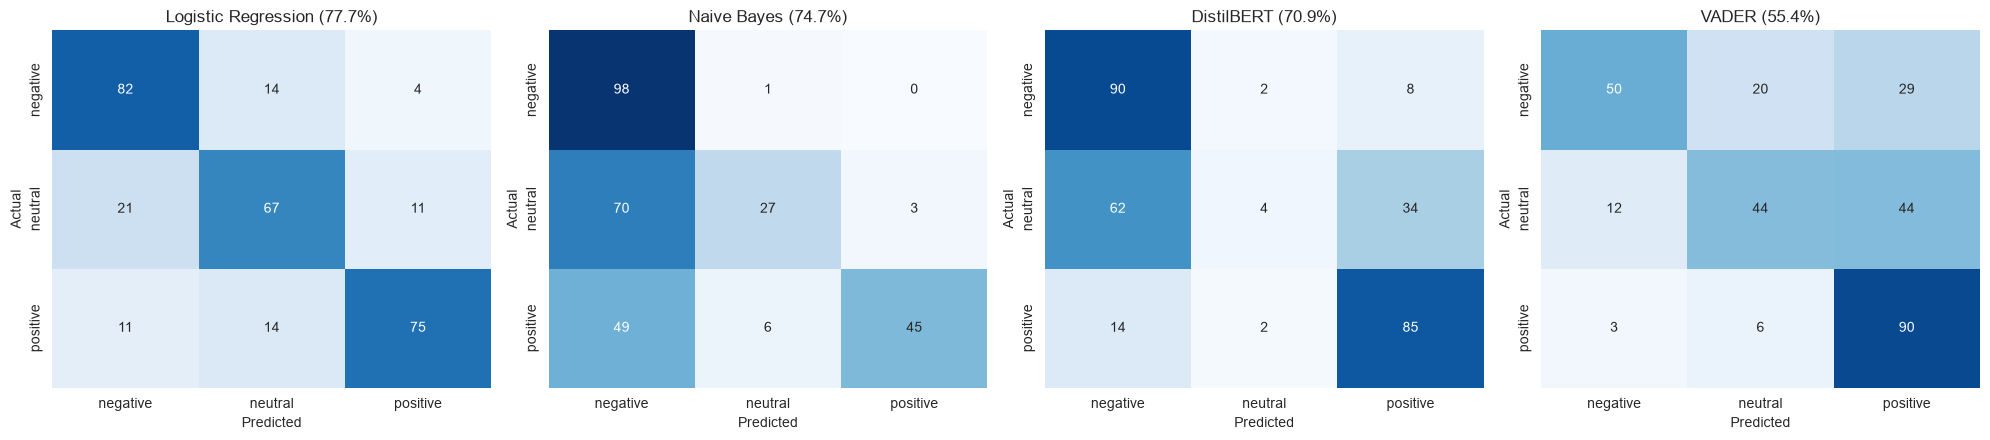

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(y_test, predictions[name], labels=SENTIMENTS)
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(pct, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False,
                xticklabels=SENTIMENTS, yticklabels=SENTIMENTS, ax=ax)
    ax.set(title=f"{name} ({results.loc[name, 'accuracy_pct']:.1f}%)", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()

**Findings:**
- **VADER** catches only half of the negative tweets and labels many of them positive.
- **Naive Bayes** leans heavily toward the majority class: it finds almost all negative tweets but only about a quarter of neutral ones.
- **DistilBERT** almost never predicts neutral, because it was trained for positive vs negative only.
- **Logistic Regression** is the most balanced across the three classes, helped by `class_weight='balanced'`.
- **Neutral is the hardest class for every model**: neutral tweets often look like polite complaints or questions, and even annotators disagree on them.

## 6. Error analysis

The most common mistakes of Logistic Regression, with examples.

In [10]:
lr_pred = pd.Series(predictions["Logistic Regression"], index=test.index)
errors = test.assign(predicted=lr_pred)[lambda d: d["sentiment"] != d["predicted"]]
patterns = errors.groupby(["sentiment", "predicted"]).size().sort_values(ascending=False).rename("tweets")
patterns.reset_index().rename(columns={"sentiment": "actual"})

,actual,predicted,tweets
0,negative,neutral,254
1,neutral,negative,131
2,negative,positive,76
3,neutral,positive,68
4,positive,neutral,66
5,positive,negative,49


In [11]:
for (actual, predicted), count in patterns.head(3).items():
    print(f"Actual {actual}, predicted {predicted} ({count} tweets)")
    for text in errors.loc[(errors["sentiment"] == actual) & (errors["predicted"] == predicted), "text"].head(4):
        print(f"  - {text}")
    print()

Actual negative, predicted neutral (254 tweets)
  - @AmericanAir yeah, buy me a @Delta plane ticket from San Diego to Detroit so I can fly one of their planes home tomorrow
  - @SouthwestAir    Promotion e-mail today (Vegas and Jamaica) has a defective link for the Vegas sweepstakes...it times out with error.
  - @USAirways hello! I never received a confirmation code for my flights (though they are confirmed--so says the automated reply). Any ideas?
  - @AmericanAir @Cowboycerrone  ratchet airway!. ......

Actual neutral, predicted negative (131 tweets)
  - @AmericanAir Considering it was past midnight, I hung up and called again to receive another service call.
  - @united I need the phone number to baggage claim in LAX, my mom left her phone and someone called saying they would put it there but on
  - @SouthwestAir quick question - i bought wifi for my phone, do I have to buy it again on my tablet? I have 9 hours left on my trip
  - @SouthwestAir how do I find travel funds I have ava

**Why the model gets these wrong:**
1. **Positive words in a complaint:** "*…let alone be courteous or helpful*" is negative, but *courteous* and *helpful* pull it toward positive.
2. **Complaints phrased as questions or facts:** a missing confirmation code or "*no internet*" is labeled negative but contains no clearly negative words.
3. **Ambiguous labels:** some tweets labeled neutral read like complaints, so annotators themselves may disagree.
4. **Very short tweets and slang** give the model almost nothing to work with.

For a social care team, the costliest error is a **negative tweet predicted as neutral** (the largest pattern), because a complaint could be missed. The next section shows how to reduce that risk.

## 7. Model agreement

When the four models agree, the prediction is more likely to be right, so agreement can serve as a confidence signal.

In [12]:
votes = pd.DataFrame({name: pd.Series(predictions[name], index=test.index) for name in MODELS})
agreement = votes.apply(lambda row: row.value_counts().iloc[0], axis=1)
lr_correct = votes["Logistic Regression"] == y_test
pd.DataFrame({
    "tweets": agreement.value_counts().sort_index(),
    "share_pct": (agreement.value_counts(normalize=True).sort_index() * 100).round(1),
    "lr_accuracy_pct": (lr_correct.groupby(agreement).mean() * 100).round(1),
}).rename_axis("models that agree")

,tweets,share_pct,lr_accuracy_pct
models that agree,,,
2,745,25.8,55.8
3,1098,38.0,76.1
4,1050,36.3,95.0


In [13]:
def majority_vote(models: list[str]) -> pd.Series:
    """Most common label among the models; ties go to Logistic Regression."""
    def vote(row):
        counts = row.value_counts()
        tied = counts[counts == counts.iloc[0]].index
        return counts.index[0] if len(tied) == 1 else row["Logistic Regression"]
    return votes[models].apply(vote, axis=1)


ensembles = {
    "Logistic Regression alone": votes["Logistic Regression"],
    "Vote of all four models": majority_vote(MODELS),
    "Vote of LR, Naive Bayes, VADER": majority_vote(["Logistic Regression", "Naive Bayes", "VADER"]),
}
pd.Series({name: accuracy_score(y_test, pred) * 100 for name, pred in ensembles.items()}, name="accuracy_pct").round(1)

Logistic Regression alone         77.7
Vote of all four models           79.8
Vote of LR, Naive Bayes, VADER    80.1
Name: accuracy_pct, dtype: float64

**Findings:**
- When **all four models agree** (36% of tweets), Logistic Regression is right **95%** of the time; when **only two agree** (26%), just **56%**. A social care tool could act automatically on high-agreement tweets and send low-agreement ones to a person.
- **A majority vote is about 2 points more accurate than Logistic Regression alone** (79.8% with all four models). The vote of the three light models, without DistilBERT, does as well (80.1%) and would still be cheap to deploy.
- **Caveat:** the vote rule (ties go to Logistic Regression) was compared on the same test set it is scored on, and the result depends on that rule. Before replacing the dashboard model, the vote should be confirmed with cross-validation on the training data.

## 8. Choice and saved model

**Logistic Regression** is used in the dashboard:
1. **Most accurate single model** (77.7%) and best F1 on every class.
2. **Fast:** trains in under a second; DistilBERT needs about a minute just to label the test set on a CPU.
3. **Explainable:** the coefficients show which words drive each prediction.
4. **Easy to deploy:** two small files, no GPU, no deep learning libraries.

The TF-IDF vectorizer and the model are saved for `src/predict.py`.

In [14]:
models_dir = Path("../models")
with open(models_dir / "tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)
with open(models_dir / "logistic_regression.pkl", "wb") as f:
    pickle.dump(lr_model, f)
print("Saved models/tfidf_vectorizer.pkl and models/logistic_regression.pkl")

Saved models/tfidf_vectorizer.pkl and models/logistic_regression.pkl
